In [8]:
import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
import matplotlib.pyplot as plt


In [ ]:
tickers = ["IBM","AAPL","MSFT","INTC","^GSPC"]

prices = yf.download(
    tickers,
    start="2018-01-01",
    auto_adjust=True,
    progress=False
)["Close"]

prices.head()


Ticker,AAPL,IBM,INTC,MSFT,^GSPC
Date,,,,,
2018-01-02,40.267078,102.657272,39.330383,78.699898,2695.810059
2018-01-03,40.260071,105.479103,37.995575,79.066170,2713.060059
2018-01-04,40.447060,107.615456,37.298813,79.762085,2723.989990
2018-01-05,40.907574,108.141167,37.559048,80.750954,2743.149902
2018-01-08,40.755642,108.793388,37.559048,80.833374,2747.709961


In [ ]:
returns = np.log(prices / prices.shift(1)).dropna()

rf_annual = 0.03
rf_daily = rf_annual / 252

excess = returns.sub(rf_daily)

market = excess["^GSPC"]

ibm = excess["IBM"]
apple = excess["AAPL"]
msft = excess["MSFT"]
intel = excess["INTC"]

weights = np.array([0.20,0.30,0.25,0.25])

portfolio = excess[["IBM","AAPL","MSFT","INTC"]] @ weights


In [ ]:
def run_capm(asset, market):

    X = sm.add_constant(market)

    model = sm.OLS(asset, X).fit()

    alpha = model.params["const"]
    beta = model.params["^GSPC"]

    return {
        "model": model,
        "alpha": alpha,
        "beta": beta,
        "adj_r2": model.rsquared_adj
    }


In [ ]:
capm_ibm = run_capm(ibm, market)

print("IBM")
print("Alpha:", capm_ibm["alpha"])
print("Beta :", capm_ibm["beta"])
print("Adj R²:", capm_ibm["adj_r2"])


IBM
Alpha: -4.5041477802922855e-07
Beta : 0.8235938928026071
Adj R²: 0.31977211735670474


In [ ]:
capm_apple = run_capm(apple, market)
capm_msft = run_capm(msft, market)
capm_intel = run_capm(intel, market)
capm_portfolio = run_capm(portfolio, market)

summary = pd.DataFrame({
    "Alpha":[
        capm_ibm["alpha"],
        capm_apple["alpha"],
        capm_msft["alpha"],
        capm_intel["alpha"],
        capm_portfolio["alpha"]
    ],
    "Beta":[
        capm_ibm["beta"],
        capm_apple["beta"],
        capm_msft["beta"],
        capm_intel["beta"],
        capm_portfolio["beta"]
    ],
    "Adj_R2":[
        capm_ibm["adj_r2"],
        capm_apple["adj_r2"],
        capm_msft["adj_r2"],
        capm_intel["adj_r2"],
        capm_portfolio["adj_r2"]
    ]
},
index=["IBM","Apple","Microsoft","Intel","Portfolio"])

summary.round(4)


,Alpha,Beta,Adj_R2
IBM,-0.0000,0.8236,0.3198
Apple,0.0004,1.2013,0.5860
Microsoft,0.0002,1.1651,0.6224
Intel,-0.0000,1.3628,0.3082
Portfolio,0.0002,1.1571,0.7550


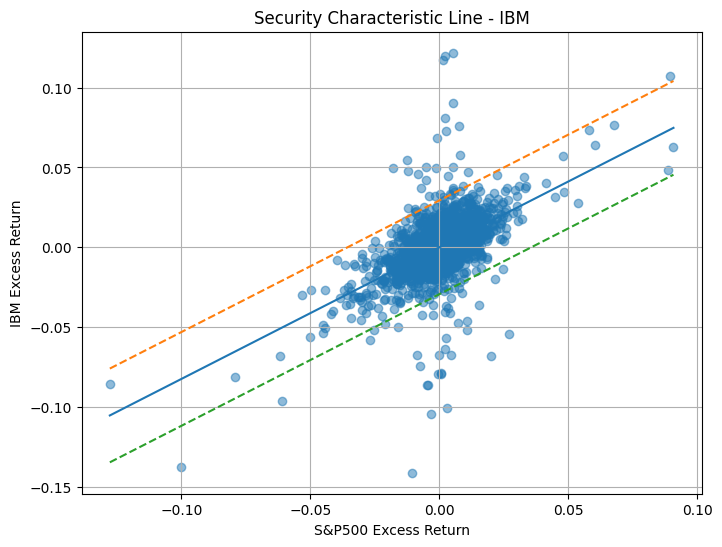

In [ ]:
model = capm_ibm["model"]

plt.figure(figsize=(8,6))

plt.scatter(market, ibm, alpha=0.5)

x = np.linspace(market.min(), market.max(), 100)

y = model.params["const"] + model.params["^GSPC"] * x

plt.plot(x, y)

rse = np.sqrt(model.mse_resid)

plt.plot(x, y + 2*rse, linestyle="--")
plt.plot(x, y - 2*rse, linestyle="--")

plt.xlabel("S&P500 Excess Return")
plt.ylabel("IBM Excess Return")
plt.title("Security Characteristic Line - IBM")

plt.grid(True)
plt.show()



Using CAPM:

- Alpha measures abnormal return.
- Beta measures market sensitivity.
- Adjusted R² measures how much variation is explained by the market.

The portfolio CAPM regression provides the portfolio alpha, beta, and explanatory power against the S&P 500 benchmark exactly as in the R exercise.
